# **2. Khám phá dữ liệu (EDA)**

Vẽ biểu đồ để hiểu phân phối doanh thu và các yếu tố ảnh hưởng. Notebook này **không thay đổi dữ liệu**.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

FIG_DIR = Path('figures')  # [UPDATED] Thư mục lưu hình để chèn vào báo cáo
FIG_DIR.mkdir(exist_ok=True)

PROCESSED_DIR = Path('data/processed')
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
NO_COMPETITOR_DISTANCE = 999999

def save_fig(name):
    """[UPDATED] Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)


# [UPDATED] Đọc dữ liệu sạch do notebook 01 lưu, nên notebook này chạy độc lập được
my_data = pd.read_csv('data/processed/rossmann_clean.csv', parse_dates=['Date'], dtype={'StateHoliday': str})
my_data = my_data.drop('Open' , axis = 1 )
my_data = my_data[my_data['Sales'] > 0]
print(my_data.shape)

(844338, 17)


**2.1 Phân phối của doanh thu (Sales)**

count    844338.0
mean       6956.0
std        3103.8
min          46.0
25%        4859.0
50%        6369.0
75%        8360.0
max       41551.0
Name: Sales, dtype: float64
Độ lệch (skewness): 1.59


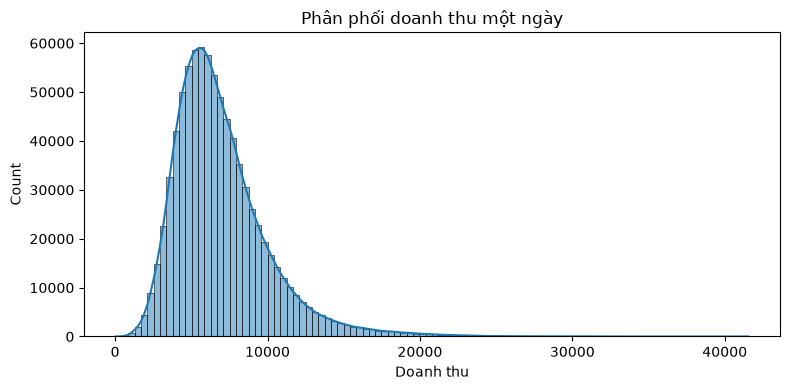

In [3]:
print(my_data['Sales'].describe().round(1))
print('Độ lệch (skewness):', round(my_data['Sales'].skew(), 2))
plt.figure(figsize=(8, 4))
sns.histplot(my_data['Sales'], bins=100, kde=True)
plt.title('Phân phối doanh thu một ngày')
plt.xlabel('Doanh thu')
save_fig('sales_hist')

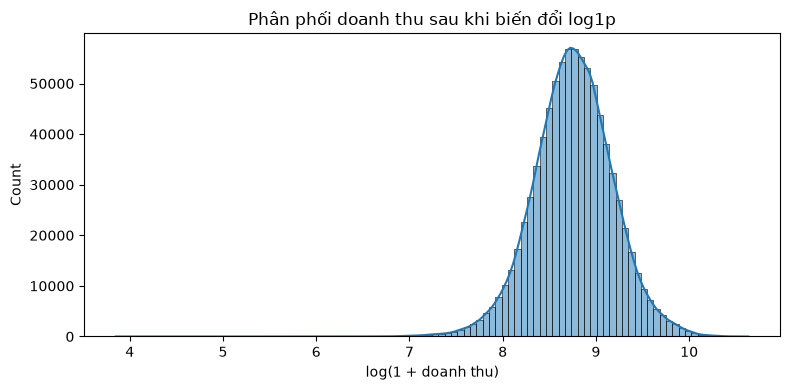

In [4]:
# [UPDATED] Chỉ vẽ phân phối sau log, KHÔNG ghi đè cột Sales (trước đây ghi đè làm các biểu đồ sau bị vẽ trên thang log)
plt.figure(figsize=(8, 4))
sns.histplot(np.log1p(my_data['Sales']), bins=100, kde=True)
plt.title('Phân phối doanh thu sau khi biến đổi log1p')
plt.xlabel('log(1 + doanh thu)')
save_fig('sales_log_hist')

**Nhận xét:** doanh thu trung bình 6.956, trung vị 6.369, độ lệch 1,59 → phân phối **lệch phải** (ít ngày doanh thu rất cao kéo đuôi bên phải). Sau `log1p` phân phối cân đối hơn, nên mô hình sẽ học trên log(doanh thu).

**2.2 Khuyến mãi và loại cửa hàng**

Tỷ lệ quan sát (%): {0: 55.36, 1: 44.64}
         mean  median
Promo                
0      5930.0  5459.0
1      8229.0  7650.0


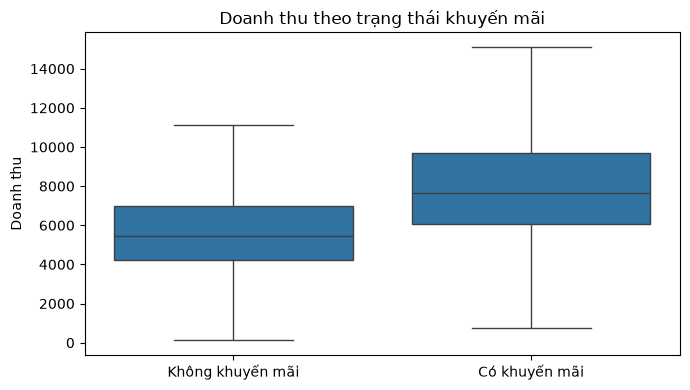

In [5]:
promo_share = my_data['Promo'].value_counts(normalize=True).mul(100).round(2)
print('Tỷ lệ quan sát (%):', promo_share.to_dict())
print(my_data.groupby('Promo')['Sales'].agg(['mean', 'median']).round(0))
plt.figure(figsize=(7, 4))
sns.boxplot(data=my_data, x='Promo', y='Sales', showfliers=False)
plt.xticks([0, 1], ['Không khuyến mãi', 'Có khuyến mãi'])
plt.xlabel('')
plt.ylabel('Doanh thu')
plt.title('Doanh thu theo trạng thái khuyến mãi')
save_fig('promo_box')

**Nhận xét:** 44,64% số ngày có khuyến mãi. Doanh thu trung bình ngày có khuyến mãi là 8.229, cao hơn khoảng 39% so với ngày không có (5.930). Hai hộp vẫn chồng lên nhau nên không phải ngày khuyến mãi nào cũng cao hơn.

           count  median     mean
StoreType                        
a            602  6481.0   6913.0
b             17  9745.0  10112.0
c            148  6646.0   6918.0
d            348  6695.0   6824.0


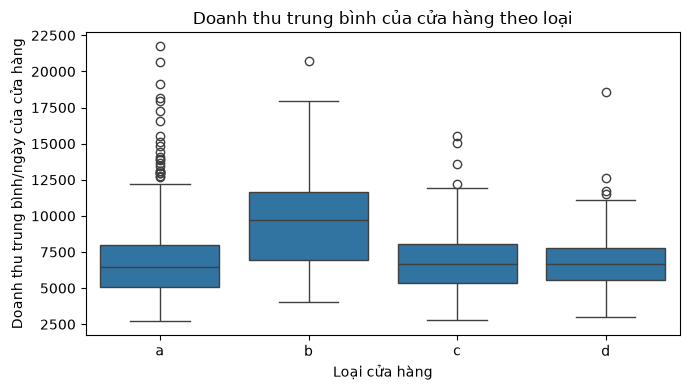

In [6]:
# [UPDATED] Sửa lỗi gom nhóm: tính doanh thu trung bình của MỖI CỬA HÀNG (trước đây gom theo giá trị Sales nên sai)
store_mean = my_data.groupby(['StoreType', 'Store'], as_index=False)['Sales'].mean()
print(store_mean.groupby('StoreType')['Sales'].agg(['count', 'median', 'mean']).round(0))
plt.figure(figsize=(7, 4))
sns.boxplot(data=store_mean, x='StoreType', y='Sales', order=['a', 'b', 'c', 'd'])
plt.xlabel('Loại cửa hàng')
plt.ylabel('Doanh thu trung bình/ngày của cửa hàng')
plt.title('Doanh thu trung bình của cửa hàng theo loại')
save_fig('storetype_box')

**Nhận xét:** loại b (chỉ 17 cửa hàng) có doanh thu trung bình/ngày cao nhất (trung vị 9.745); ba loại a, c, d gần như ngang nhau (khoảng 6.500–6.700).

**2.3 Doanh thu theo thời gian**

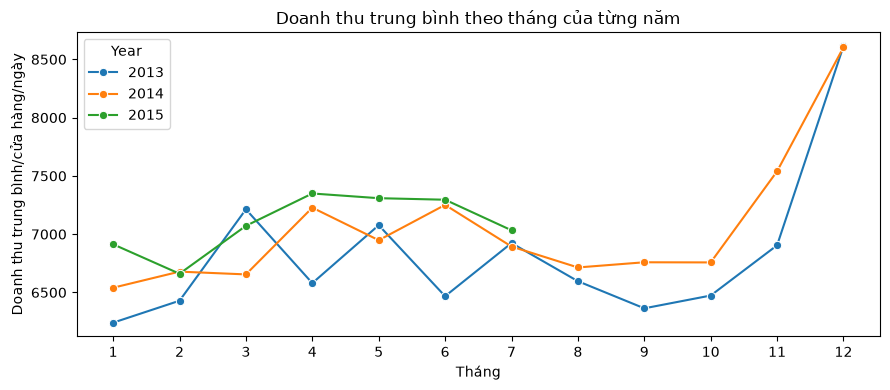

In [7]:
# [UPDATED] Dùng doanh thu TRUNG BÌNH thay vì tổng: 180 cửa hàng thiếu dữ liệu 07–12/2014 làm tổng doanh thu giảm giả tạo
monthly = my_data.set_index('Date')['Sales'].resample('MS').mean().reset_index()
monthly['Year'] = monthly['Date'].dt.year
monthly['Month'] = monthly['Date'].dt.month
plt.figure(figsize=(9, 4))
sns.lineplot(data=monthly, x='Month', y='Sales', hue='Year', marker='o', palette='tab10')
plt.xticks(range(1, 13))
plt.xlabel('Tháng')
plt.ylabel('Doanh thu trung bình/cửa hàng/ngày')
plt.title('Doanh thu trung bình theo tháng của từng năm')
save_fig('monthly_sales')

**Nhận xét:** doanh thu tăng mạnh vào tháng 11–12 (mùa lễ cuối năm) và lặp lại ở cả 2013, 2014. Năm 2015 nhìn chung cao hơn cùng kỳ các năm trước → có xu hướng tăng nhẹ. *Lưu ý:* nếu vẽ bằng tổng doanh thu, nửa cuối 2014 sẽ thấp giả tạo do 180 cửa hàng bị thiếu dữ liệu.

             size    mean  median
DayOfWeek                        
1          137557  8216.0  7539.0
2          143955  7088.0  6502.0
3          141922  6729.0  6210.0
4          134626  6768.0  6246.0
5          138633  7073.0  6581.0
6          144052  5875.0  5425.0
7            3593  8225.0  6876.0


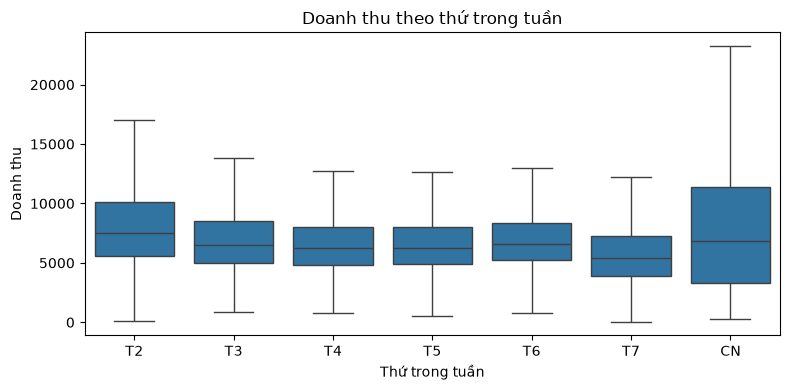

In [8]:
print(my_data.groupby('DayOfWeek')['Sales'].agg(['size', 'mean', 'median']).round(0))
plt.figure(figsize=(8, 4))
sns.boxplot(data=my_data, x='DayOfWeek', y='Sales', showfliers=False)
plt.xticks(range(7), ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN'])
plt.xlabel('Thứ trong tuần')
plt.ylabel('Doanh thu')
plt.title('Doanh thu theo thứ trong tuần')
save_fig('dow_box')

**Nhận xét:** thứ Hai bán chạy nhất (trung bình 8.216), thứ Bảy thấp nhất (5.875). Chủ nhật chỉ có 3.593 quan sát vì phần lớn cửa hàng đóng cửa, nên con số của Chủ nhật không đại diện cho cả chuỗi.

**2.4 Quan hệ giữa các biến**

Customers                    0.824
Promo                        0.368
SchoolHoliday                0.039
CompetitionOpenSinceYear     0.016
CompetitionDistance         -0.036
CompetitionOpenSinceMonth   -0.043
Promo2                      -0.128
DayOfWeek                   -0.179
Name: Sales, dtype: float64


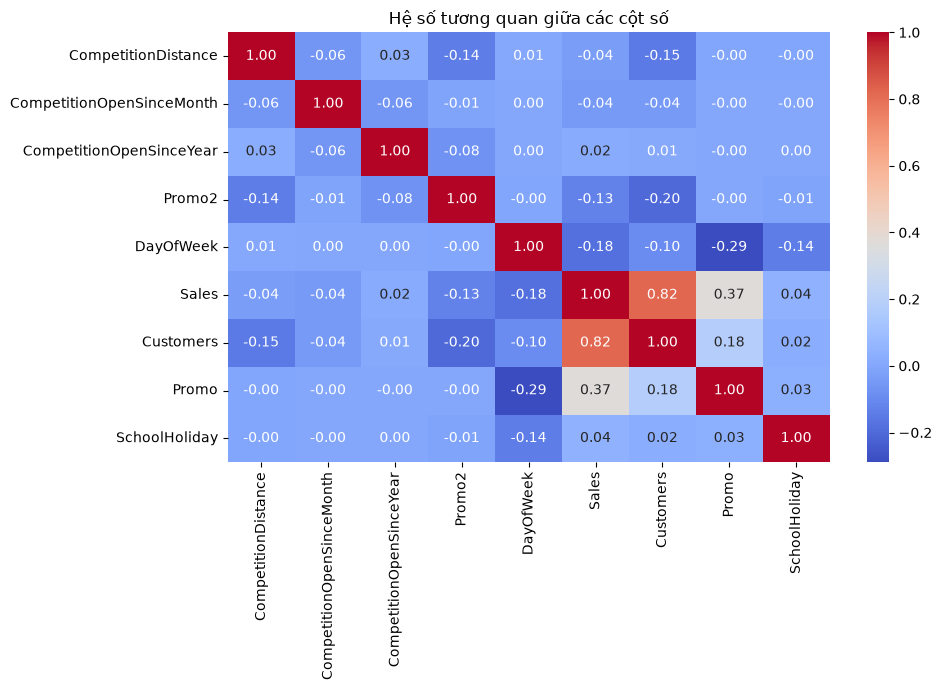

In [9]:
# [UPDATED] Chỉ lấy cột số (numeric_only) để tránh lỗi với cột ngày và cột chữ
cols = [c for c in my_data.select_dtypes('number').columns
        if c not in ['Store', 'Promo2SinceWeek', 'Promo2SinceYear']]
corr = my_data[cols].corr()
print(corr['Sales'].drop('Sales').sort_values(ascending=False).round(3))
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Hệ số tương quan giữa các cột số')
save_fig('corr_heatmap')

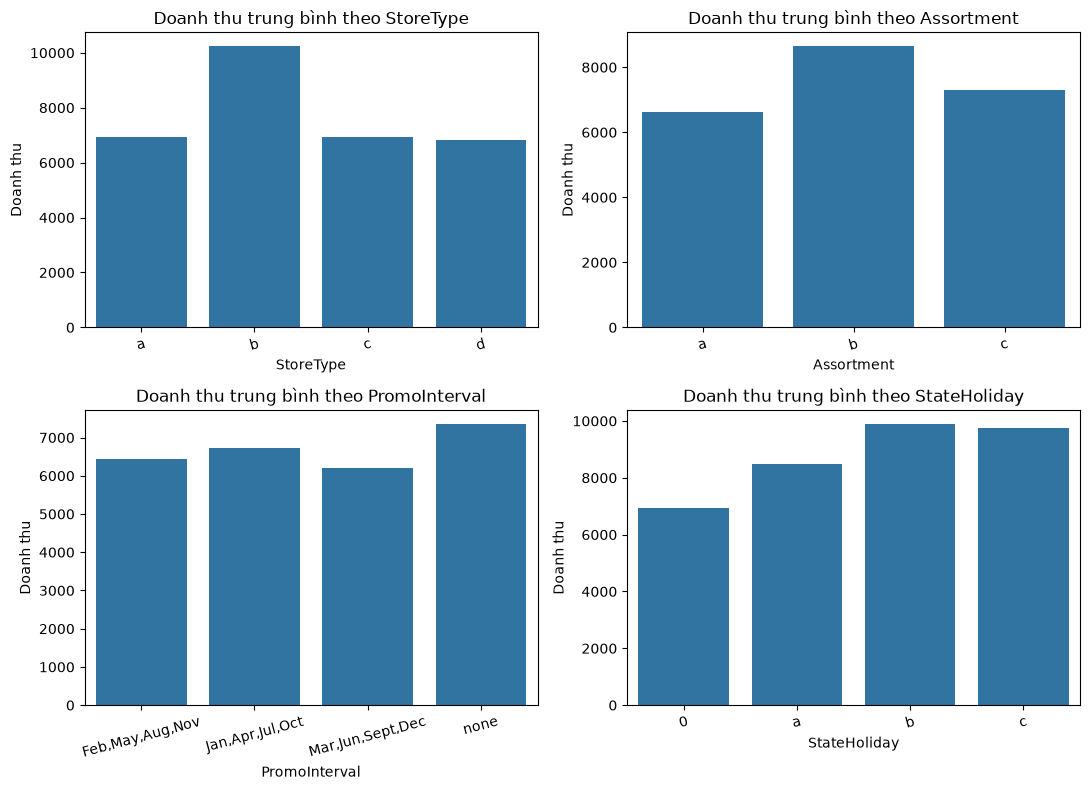

In [10]:
plot_df = my_data[['Sales']].copy()
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flatten(), ['StoreType', 'Assortment', 'PromoInterval', 'StateHoliday']):
    plot_df[col] = my_data[col].fillna('none').astype(str)
    sns.barplot(data=plot_df, x=col, y='Sales', ax=ax, errorbar=None,
                order=sorted(plot_df[col].unique()))
    ax.set_title(f'Doanh thu trung bình theo {col}')
    ax.set_ylabel('Doanh thu')
    ax.tick_params(axis='x', labelrotation=15)
save_fig('category_bars')

**Nhận xét:** `Customers` tương quan rất mạnh với doanh thu (0,82) nhưng chỉ biết sau khi bán xong → không dùng để dự đoán. `Promo` có tương quan dương rõ nhất (0,37) trong các cột còn lại. Ngày lễ (a, b, c) có doanh thu trung bình cao hơn ngày thường vì chỉ một số ít cửa hàng mở cửa vào ngày lễ.

**2.5 Khảo sát chuỗi thời gian trong tập dữ liệu.**

Làm mượt dữ liệu và quan sát các xu hướng dài hạn.

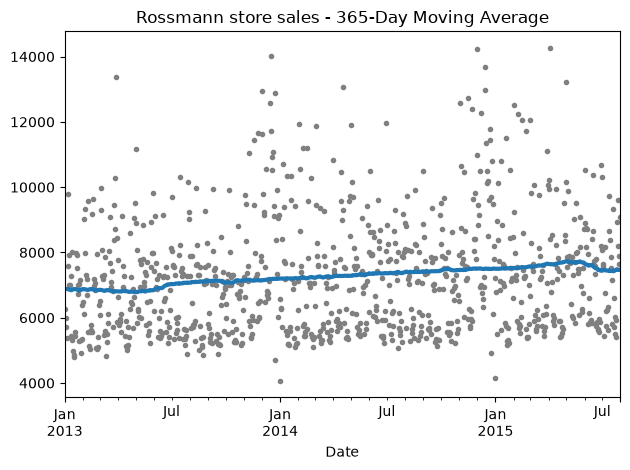

In [11]:
daily_sales = my_data.groupby('Date')['Sales'].mean()
moving_average = daily_sales.rolling(
    window = 365 ,
    center = True ,
    min_periods = 183
).mean()
ax = daily_sales.plot(style=".", color="0.5")
moving_average.plot(
    ax=ax, linewidth=3, title="Rossmann store sales - 365-Day Moving Average", legend=False,
)
save_fig('365_Day_Moving_Average')

Đường trung bình động không di chuyển ngang hoặc có xu hướng đi xuống mà thay vào đó tăng đều đặn theo thời gian và hầu như không bị ảnh hưởng bởi nhiễu cho thấy chuỗi cửa hàng đang trên quỹ đạo tăng trưởng. Trong khi đó, sự phân tán dữ liệu đồng đều cho thấy mô hình hoạt động kinh doanh có tính nhất quán cao qua các năm. Song, xu hướng còn khá yếu có tăng nhẹ, nhưng nhỏ hơn nhiều so với dao động hằng ngày. Đường xanh đi từ khoảng 6000 lên khoảng 6800, gần như phẳng, trong khi các chấm xám dao động cao hơn. 

xây dựng thêm các đặc trưng dữ liệu liên quan đến xu hướng.

In [12]:
from statsmodels.tsa.deterministic import DeterministicProcess
daily_sales.index = daily_sales.index.to_period('D')
dp = DeterministicProcess(
    index = daily_sales.index ,
    constant = True ,
    order = 1 ,
    drop = True
)
my_data['Date'] = my_data['Date'].dt.to_period('D')
X_trend = dp.in_sample()
print(X_trend.head())

            const  trend
Date                    
2013-01-01    1.0    1.0
2013-01-02    1.0    2.0
2013-01-03    1.0    3.0
2013-01-04    1.0    4.0
2013-01-05    1.0    5.0


Trực quan hoá các xu hướng dài hạn.

Tăng mỗi năm ≈ 346 đơn vị doanh thu (4.8% so với mức trung bình)


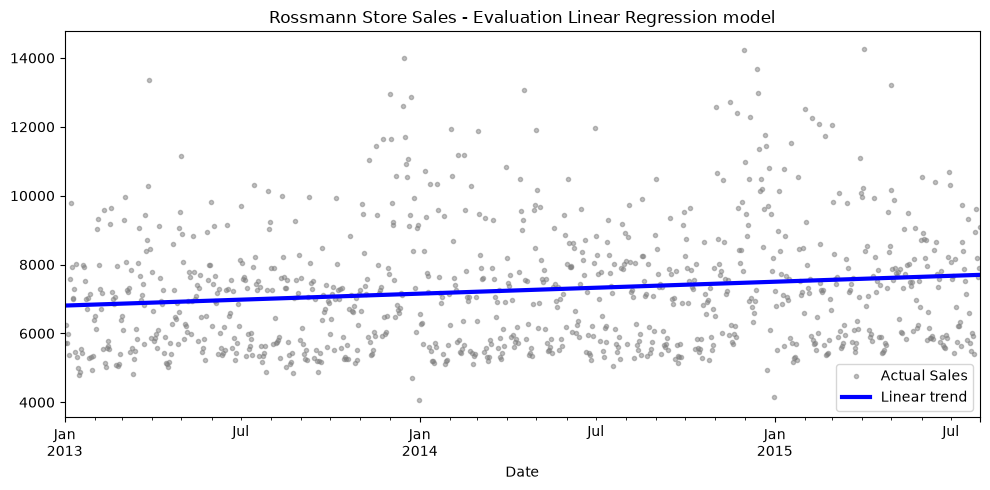

In [13]:
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=False)
y = daily_sales 
model.fit(X_trend,y)
y_pred = pd.Series(model.predict(X_trend), index=X_trend.index)
plt.figure(figsize=(10, 5))
ax = y.plot(style=".", color="0.5", alpha=0.5, label="Actual Sales")
y_pred.plot(ax=ax, linewidth=3, color="blue", label="Linear trend")
plt.title("Rossmann Store Sales - Evaluation Linear Regression model")
plt.legend()
t = np.arange(len(y))
b, a = np.polyfit(t, y, 1)
print(f'Tăng mỗi năm ≈ {b*365:,.0f} đơn vị doanh thu '
      f'({b*365 / y.mean():.1%} so với mức trung bình)')
save_fig('Evaluation_Linear_Regression_model')

Có xu hướng nhưng yếu. Các chấm xám nằm tản mát quanh đường thẳng, nên bản thân xu hướng giải thích được rất ít biến động.

Thử dự đoán doanh thu cho 30 ngày tiếp theo.

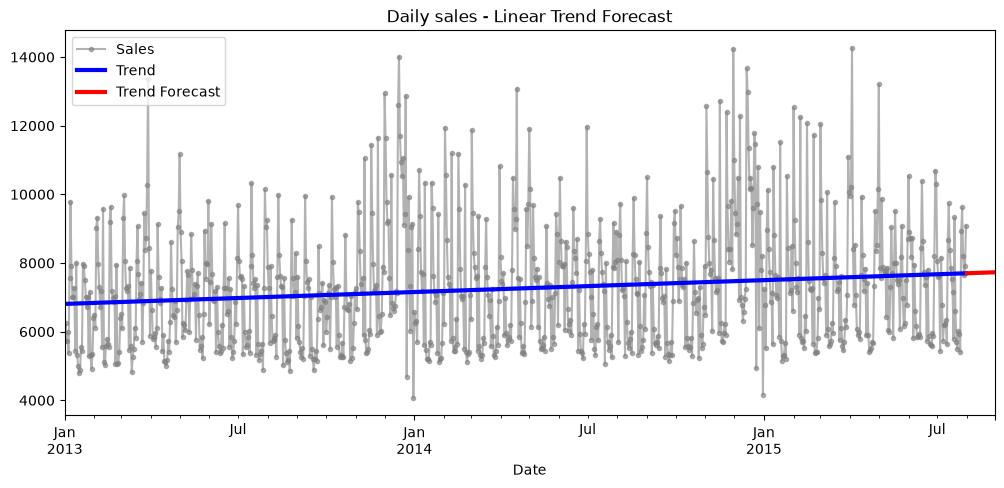

<Figure size 640x480 with 0 Axes>

In [14]:
X_trend = dp.out_of_sample(steps=30)
y_fore = pd.Series(model.predict(X_trend), index=X_trend.index)
plt.figure(figsize=(12, 5))
ax = y.plot(style=".-", color="0.5", alpha=0.6, label="Sales")
y_pred.plot(ax=ax, linewidth=3, color="blue", label="Trend")
y_fore.plot(ax=ax, linewidth=3, color="red", label="Trend Forecast")
plt.title("Daily sales - Linear Trend Forecast")
plt.legend()
plt.show()
save_fig('daily_sales_Linear_Trend_Forecast')

Giả định xu hướng cứ tiếp tục như cũ. Với 48 ngày thì phần tăng thêm chỉ khoảng 0,007, quá nhỏ so với nhiễu hằng ngày, nên đoạn đỏ gần như nằm ngang.

Vẽ biểu đồ thể hiện tác động của các ngày đối với doanh thu(Tính mùa vụ).

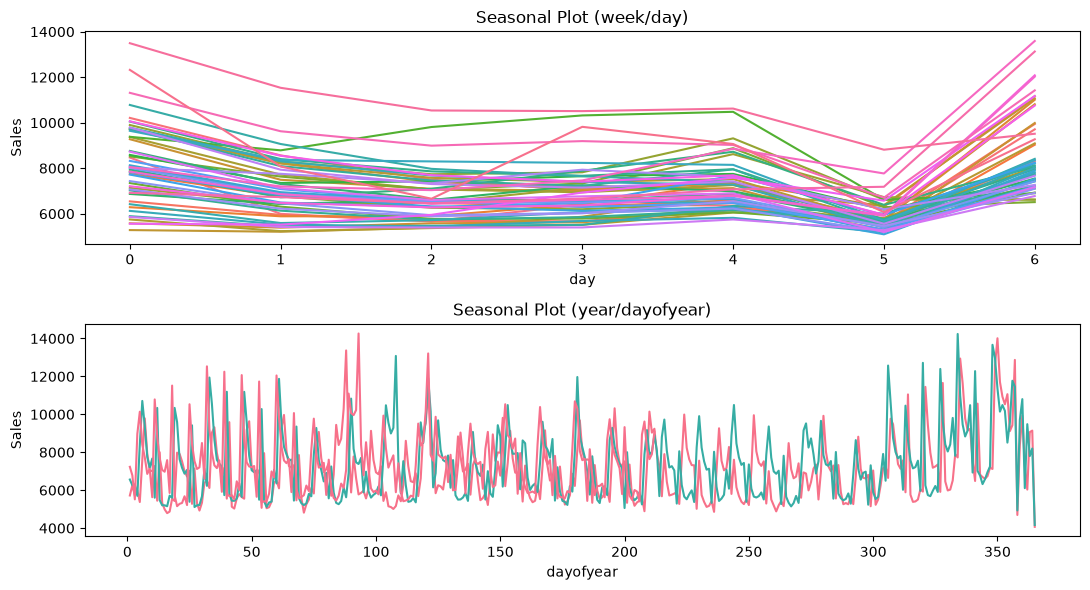

In [15]:
from statsmodels.tsa.seasonal import STL
def seasonal_plot( X , y , period , freq , ax=None ):
    if ax is None:
        fig, ax = plt.subplots()
    sns.lineplot( data = X , x = freq , y = y , hue = period , errorbar = None , palette="husl" , ax = ax , legend = False)
    ax.set_title(f'Seasonal Plot ({period}/{freq})')
    return ax
X_season = daily_sales.to_frame(name='Sales')
X_season['day'] = X_season.index.dayofweek
X_season['week'] = X_season.index.week
X_season['dayofyear'] = X_season.index.dayofyear
X_season['year'] = X_season.index.year
fig, (ax0 , ax1) = plt.subplots(2 , 1 , figsize = (11 , 6))
seasonal_plot(X_season , y = 'Sales' , period = 'week' , freq = 'day' , ax = ax0 )
seasonal_plot(X_season , y = 'Sales' , period = 'year' , freq = 'dayofyear' , ax = ax1 )
plt.tight_layout()
save_fig('seasonal_plot')

Biểu đồ mùa vụ theo tuần. Với mỗi đường ngang là một tuần, trục ngang là thứ trong tuần. Các đường chạy gần như song song: thứ Hai cao nhất, giảm dần đến thứ Sáu, rớt xuống đáy ở thứ Bảy (5), rồi vọt lên ở Chủ nhật (6). Vì các đường chồng sát nhau, chu kỳ tuần rất ổn định và mạnh.

Biểu đồ mùa vụ theo năm do bị ảnh hưởng bởi tính mùa vụ theo từng nên biểu đồ khá rối. Chỉ thấy mơ hồ đợt tăng ở khoảng ngày 340–350 (trước Giáng sinh). Cần kiểm chứng thêm biểu đồ trung bình trượt 7 ngày hoặc trung bình theo tuần để loại chu kỳ tuần nhằm đánh giá đúng hơn về tính mùa vụ theo năm.

Hãy xem xét biểu đồ chu kỳ (periodogram)

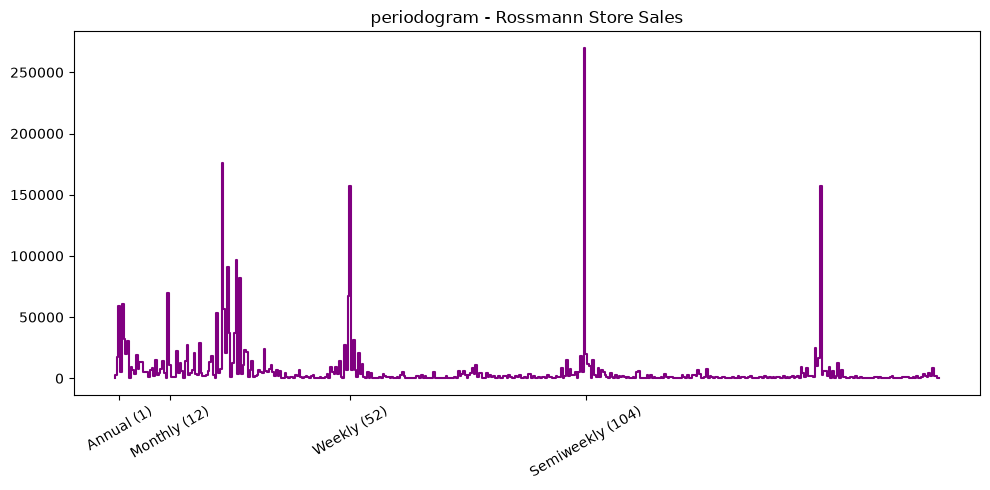

In [16]:
from scipy.signal import periodogram
def plot_periodogram(ts, detrend='linear', ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    frequencies, variance = periodogram( ts, detrend=detrend, scaling='spectrum')
    ax.step(frequencies, variance, color="purple")
    ax.set_title('periodogram - Rossmann Store Sales')
    periods = [365, 30, 7, 3.5]
    x_ticks = [1 / p for p in periods]
    x_labels = ['Annual (1)', 'Monthly (12)', 'Weekly (52)', 'Semiweekly (104)']
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels, rotation=30)
    return ax
plot_periodogram( X_season['Sales'] )
save_fig('periodogram_Rossmann_Store_Sales')

Xu hướng cao nhất nằm ở mốc 104(nửa tuần) thay vì 52( cả tuần ). Vì thế, mẫu hình trong tuần không phải một sóng sin đơn giản, mà có hai chỗ lên xuống (thứ Hai cao, thứ Bảy thấp, Chủ nhật cao). Đây là lý do vài cặp sin/cos khớp tuần kém, và dùng DayOfWeek sẽ khớp tuần tốt hơn. 

Cụm đỉnh quanh 23–27 chu kỳ/năm tương ứng chu kỳ khoảng hai tuần cần kiểm định lại vì nó khớp với việc khuyến mãi Rossmann chạy theo chu kỳ hai tuần, có thể thêm các đặc trưng liên quan đến ngày gần khuyến mãi sẽ tốt hơn thay vì dùng fourier .Ngoài ra, đỉnh 1(năm) có xu hướng thấp cho thấy tính mùa vụ theo năm tương đối yếu.

Tạo đặc trưng mùa vụ.

In [17]:
from statsmodels.tsa.deterministic import CalendarFourier
fourier_annual = CalendarFourier(freq = 'YE' , order = 10 )
fourier_month = CalendarFourier(freq = 'W' , order = 2 )
dp = DeterministicProcess(
    index = X_season.index ,
    constant = True ,
    order = 1,
    seasonal = True ,
    additional_terms = [ fourier_annual , fourier_month ] ,
    drop = True
)
X_fourier = dp.in_sample()
X_fourier.head()

,const,trend,"s(2,7)","s(5,7)","sin(1,freq=YE-DEC)","cos(1,freq=YE-DEC)","sin(2,freq=YE-DEC)","cos(2,freq=YE-DEC)","sin(3,freq=YE-DEC)","cos(3,freq=YE-DEC)",...,"sin(8,freq=YE-DEC)","cos(8,freq=YE-DEC)","sin(9,freq=YE-DEC)","cos(9,freq=YE-DEC)","sin(10,freq=YE-DEC)","cos(10,freq=YE-DEC)","sin(1,freq=W-SUN)","cos(1,freq=W-SUN)","sin(2,freq=W-SUN)","cos(2,freq=W-SUN)"
Date,,,,,,,,,,,,,,,,,,,,,
2013-01-01,1.0,1.0,0.0,0.0,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.781831,0.623490,0.974928,-0.222521
2013-01-02,1.0,2.0,1.0,0.0,0.017213,0.999852,0.034422,0.999407,0.051620,0.998667,...,0.137279,0.990532,0.154309,0.988023,0.171293,0.985220,0.974928,-0.222521,-0.433884,-0.900969
2013-01-03,1.0,3.0,0.0,0.0,0.034422,0.999407,0.068802,0.997630,0.103102,0.994671,...,0.271958,0.962309,0.304921,0.952378,0.337523,0.941317,0.433884,-0.900969,-0.781831,0.623490
2013-01-04,1.0,4.0,0.0,0.0,0.051620,0.998667,0.103102,0.994671,0.154309,0.988023,...,0.401488,0.915864,0.448229,0.893919,0.493776,0.869589,-0.433884,-0.900969,0.781831,0.623490
2013-01-05,1.0,5.0,0.0,1.0,0.068802,0.997630,0.137279,0.990532,0.205104,0.978740,...,0.523416,0.852078,0.580800,0.814046,0.635432,0.772157,-0.974928,-0.222521,0.433884,-0.900969


Trực quan hoá tính thời vụ và cố gắng dự báo doanh số bán hàng trong 30 ngày tới.

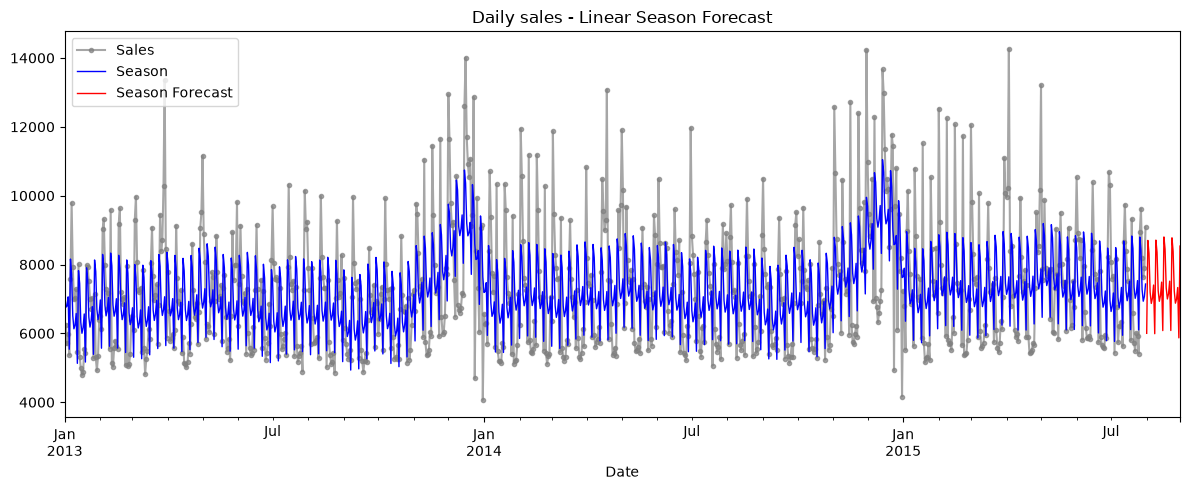

In [18]:
from sklearn.linear_model import Lasso
model_lasso = Lasso(alpha = 1.0)
model.fit(X_fourier , y)
y_pred = pd.Series( model.predict(X_fourier) , index = X_fourier.index)
X_for = dp.out_of_sample(steps = 30)
y_fore = pd.Series( model.predict(X_for) , index = X_for.index)
plt.figure(figsize=(12, 5))
ax = y.plot(style=".-", color="0.5", alpha=0.7, label="Sales")
y_pred.plot(ax=ax, linewidth=1, color="blue", label="Season")
y_fore.plot(ax=ax, linewidth=1, color="red", label="Season Forecast")
plt.title("Daily sales - Linear Season Forecast")
plt.legend()
save_fig("Daily_sales_Linear_Season_Forecast")

Doanh thu đã điều chỉnh theo các yếu tố xu hướng và mùa vụ.

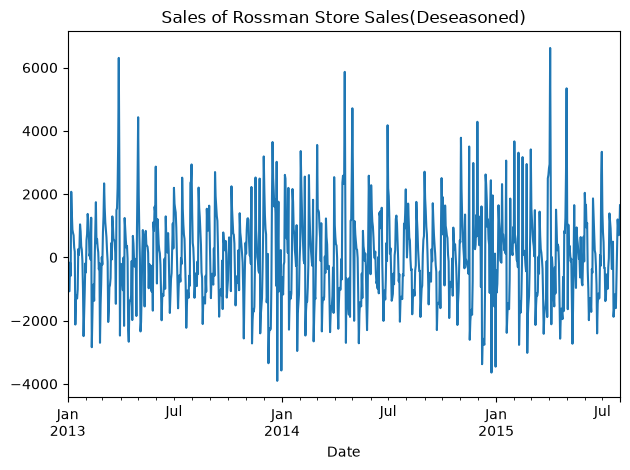

In [19]:
y_deseason = y - y_pred 
y_deseason.name = 'Sale Deseasoned'
ax = y_deseason.plot()
ax.set_title('Sales of Rossman Store Sales(Deseasoned)')
save_fig('Sales_of_Rossman_Store_Sales(Deseasoned)')

Mô hình mùa vụ chỉ giải thích được một phần, và phần còn lại vẫn có cấu trúc. Nguyên nhân có thể là chu kỳ tuần có hình dạng nhọn (thứ Bảy tụt sâu, Chủ nhật vọt lên) mà vài cặp sin/cos không tái tạo được như ở phần periodogram đã diễn giải. Dùng biến giả cho từng thứ trong tuần sẽ khớp tốt hơn.

Thực hiện làm mịn dữ liệu hàng tuần với y.

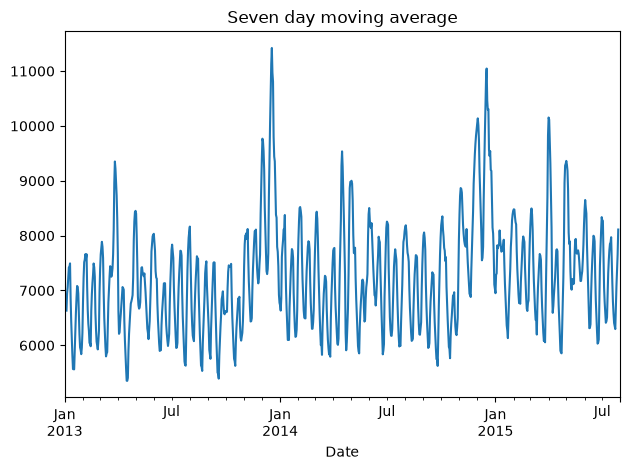

In [20]:
y_ma = y.rolling( window = 7 , center = True ).mean()
ax = y_ma.plot()
ax.set_title('Seven day moving average')
save_fig('Seven_day_moving_average')

Trung bình trượt 7 ngày xoá chu kỳ tuần, nên lẽ ra đường phải khá phẳng. Nhưng nó vẫn dao động mạnh từ khoang 6500 đến hơn 8000 với các đỉnh lặp lại dày. Có thể đưa ra giả thuyết có một chu kỳ dài hơn một tuần, khoảng hai tuần, và rất có thể do khuyến mãi (Promo) chạy theo từng đợt luân phiên hoặc do ảnh hưởng từ các tuần lễ lớn trong năm.

Đọc các quy luật về chuỗi thời gian còn lại thông qua biến độ trễ(lags).

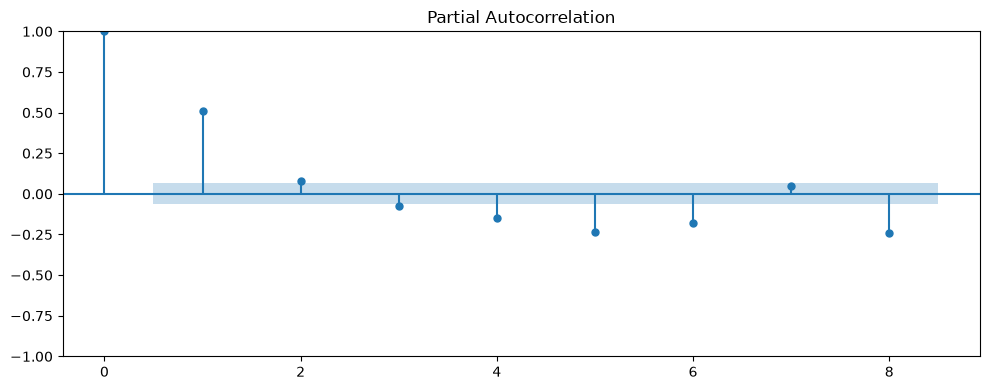

In [21]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(y_deseason, lags=8, ax=ax)
save_fig('Partial Autocorrelation')

Theo các kết quả trước, xu hướng tuần có phản ứng mạnh và nổi trội nhất do đó các biến lag theo tuần sẽ thu được nhiều thông tin hữu ích cho mô hình học đơn cử như lag 1 và lag 8. Nhưng do dự báo trên một khoảng thời gian do đó các biến lag này không thể sử dụng được vì có thể gây sai số lớn. Vì thế, các lag có thể áp dụng được trong mô hình chỉ có những lag trong horizon( ở dataset này là 48 ngày). Do đó, các lag dùng được và có tiềm nay mang lại nhiều thông tin hữu ích là 49 , 56 , 63 bám sát chu kì tuần.

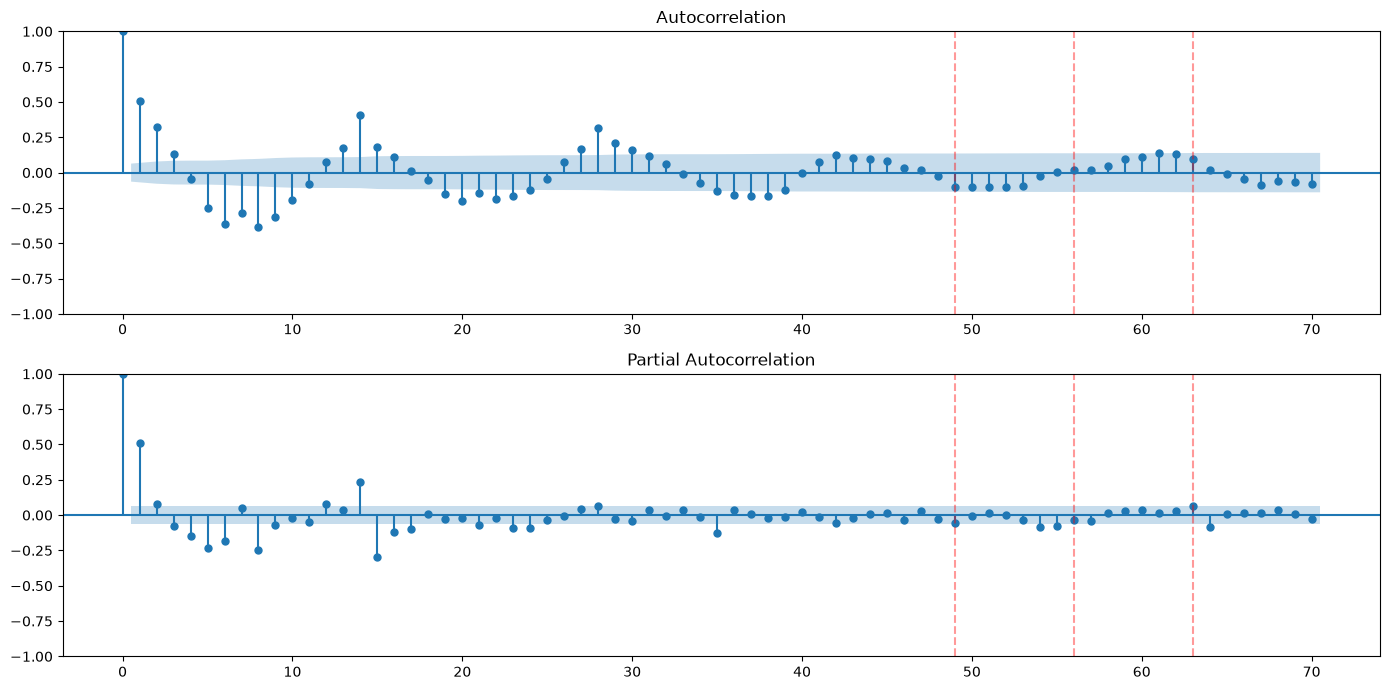

In [22]:
y_res = y_deseason.dropna()
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_acf(y_res,  lags=70, ax=axes[0])
plot_pacf(y_res, lags=70, ax=axes[1], method='ywm')
for ax in axes:
    for k in (49, 56, 63):
        ax.axvline(k, color='red', ls='--', alpha=0.4)
plt.tight_layout()
save_fig('Partial Autocorrelation Horizon')

Do horizon là một khoảng khá lớn, do đó nếu dùng các lag của horizon sẽ mang lại không nhiều thông tin hữu ích vì đã bỏ lỡ xu hướng của các tuần gần nhất. Do đó, để sử dụng hiệu quả biến lag ta cần dự đoán doanh thu theo hướng mà dùng được lag 1 và lag 8.

**Kết luận**: Chuỗi doanh thu có mùa vụ tuần mạnh (độ mạnh STL 0,65), trong khi xu hướng dài hạn rất yếu (đường thẳng giải thích 2,1% biến thiên; STL với cửa sổ 365 ngày cho 0,04). Mùa vụ năm khó biểu diễn bằng Fourier nhưng có hiệu ứng cuối năm rõ (đỉnh quanh Giáng sinh). Ngoài chu kỳ tuần còn có biến động trung hạn đáng kể (STL mặc định 0,68), nhiều khả năng liên quan đến chu kỳ khuyến mãi và ngày lễ. Vì phần biến động này có thể được biểu diễn trực tiếp bằng các đặc trưng lịch và khuyến mãi (DayOfWeek, Promo, Month, ngày lễ), chúng tôi dự đoán các đặc trưng chuỗi thời gian chuyên biệt (xu hướng, Fourier, mô hình lai) ít cải thiện độ chính xác. Đặt trưng lag cũng là một đặc trưng quan trọng trong chuỗi thời gian nhưng do bị giới hạn bởi horizon nên không thể phát huy toàn bộ khả năng của đặc trưng này. kiểm chứng điều này ở phần thử nghiệm bằng RMSPE trên tập kiểm định.

Lưu dữ liệu.

In [23]:
y_deseason.to_csv(PROCESSED_DIR / 'y_deseason.csv' , index=True)
X_fourier.to_csv(PROCESSED_DIR / 'X_fourier.csv' , index=True)
X_trend.to_csv(PROCESSED_DIR / 'X_trend.csv' , index=True)
print('Đã lưu' , PROCESSED_DIR / 'y_deseason.csv' )
print('Đã lưu' , PROCESSED_DIR / 'X_fourier.csv' )
print('Đã lưu' , PROCESSED_DIR / 'X_trend.csv' )

Đã lưu data\processed\y_deseason.csv
Đã lưu data\processed\X_fourier.csv
Đã lưu data\processed\X_trend.csv
